In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [1]:
import pandas as pd
import numpy as np

# 1. Load the raw Kaggle dataset
df = pd.read_csv("dataset.csv")

# 2. Drop index columns if present (Kaggle datasets often include an "Unnamed: 0" column)
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# 3. Handle missing values
df = df.dropna()

# 4. Remove duplicate songs (based on track ID or track_name + artists)
if "track_id" in df.columns:
    df = df.drop_duplicates(subset=["track_id"])
else:
    df = df.drop_duplicates(subset=["track_name", "artists"])

print("Cleaned Dataset Shape:", df.shape)
display(df.head())

Cleaned Dataset Shape: (89740, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


###Top Represented Genres (Track Counts)
Requirement: Count tracks across genres and identify the most represented genres

Total Unique Genres: 113

--- TOP 10 MOST REPRESENTED GENRES ---


,count
track_genre,
acoustic,1000
afrobeat,999
alt-rock,999
ambient,999
cantopop,999
tango,999
chicago-house,998
forro,998
bluegrass,998


/tmp/ipykernel_2013/1190173518.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_15_genres.values, y=top_15_genres.index, palette="viridis")


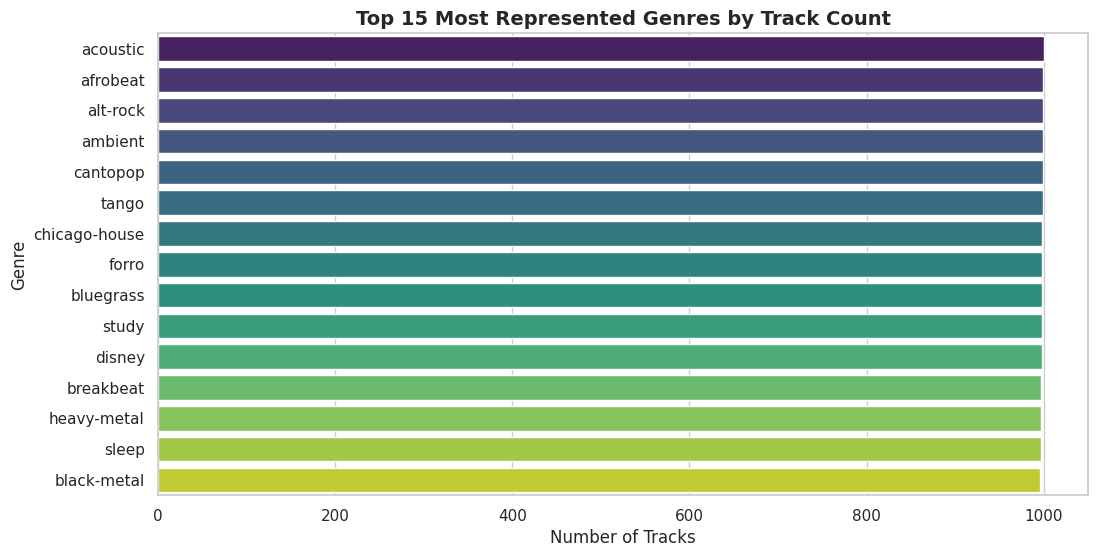

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Count tracks per genre
genre_counts = df["track_genre"].value_counts()
print("Total Unique Genres:", len(genre_counts))
print("\n--- TOP 10 MOST REPRESENTED GENRES ---")
display(genre_counts.head(10))

# 2. Bar Chart of Top 15 Genres
plt.figure(figsize=(12, 6))
top_15_genres = genre_counts.head(15)
sns.barplot(x=top_15_genres.values, y=top_15_genres.index, palette="viridis")
plt.title("Top 15 Most Represented Genres by Track Count", fontsize=14, fontweight="bold")
plt.xlabel("Number of Tracks")
plt.ylabel("Genre")
plt.show()

###Popularity & Duration Across Selected Genres
Requirement: Compare average popularity and duration across selected genres

--- AVERAGE POPULARITY & DURATION (TOP 10 GENRES) ---


,popularity,duration_sec
track_genre,,
acoustic,42.48,214.90
afrobeat,24.41,248.44
alt-rock,33.90,235.36
ambient,44.21,237.25
bluegrass,25.68,221.60
cantopop,34.75,229.23
chicago-house,12.33,366.89
forro,41.83,190.73
study,26.13,141.54


/tmp/ipykernel_2013/2907062426.py:16: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=filtered_df, x="popularity", y="track_genre", ax=axes[0], palette="magma", ci=None)
/tmp/ipykernel_2013/2907062426.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=filtered_df, x="popularity", y="track_genre", ax=axes[0], palette="magma", ci=None)
/tmp/ipykernel_2013/2907062426.py:20: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=filtered_df, x="duration_sec", y="track_genre", ax=axes[1], palette="coolwarm", ci=None)
/tmp/ipykernel_2013/2907062426.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for 

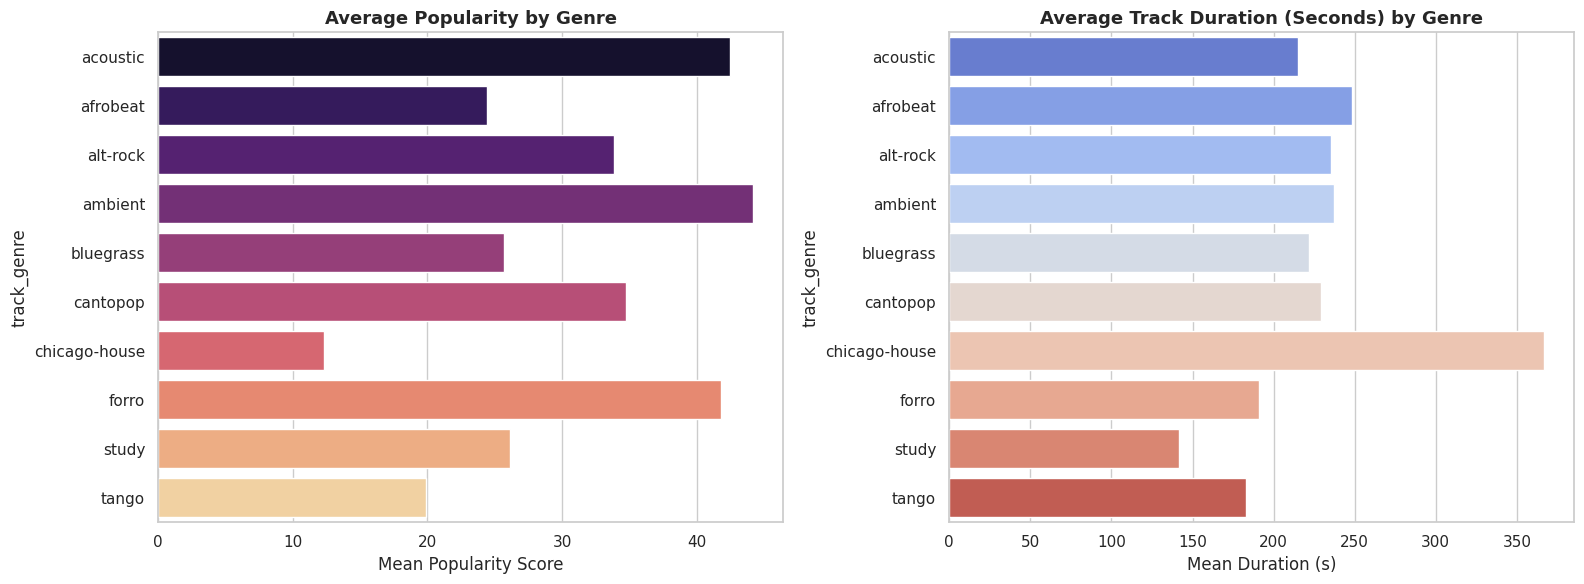

In [3]:
# Convert duration_ms to seconds for clarity
df["duration_sec"] = df["duration_ms"] / 1000

# Select Top 10 genres for comparison
top_10_genres_list = genre_counts.head(10).index.tolist()
filtered_df = df[df["track_genre"].isin(top_10_genres_list)]

# Group by genre to calculate average popularity and duration
genre_metrics = filtered_df.groupby("track_genre")[["popularity", "duration_sec"]].mean().round(2)
print("--- AVERAGE POPULARITY & DURATION (TOP 10 GENRES) ---")
display(genre_metrics)

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=filtered_df, x="popularity", y="track_genre", ax=axes[0], palette="magma", ci=None)
axes[0].set_title("Average Popularity by Genre", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Mean Popularity Score")

sns.barplot(data=filtered_df, x="duration_sec", y="track_genre", ax=axes[1], palette="coolwarm", ci=None)
axes[1].set_title("Average Track Duration (Seconds) by Genre", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Mean Duration (s)")

plt.tight_layout()
plt.show()

###Audio Features Across Genres (Bar Charts & Box Plots)
Requirement: Compare audio features across genres using bar charts and box plots


/tmp/ipykernel_2013/867811761.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=filtered_df, x="danceability", y="track_genre", ax=axes[0], palette="Set2")
/tmp/ipykernel_2013/867811761.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=filtered_df, x="energy", y="track_genre", ax=axes[1], palette="Set2")


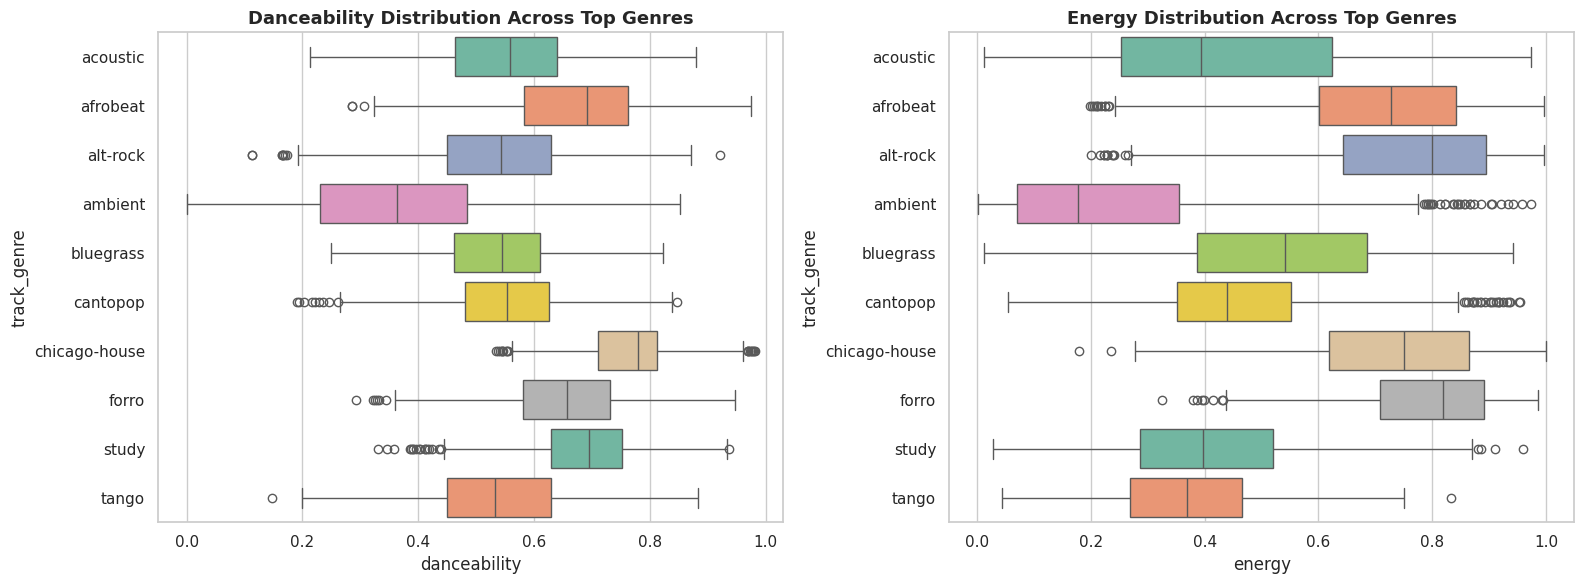

In [4]:
# Compare Danceability and Energy distributions across top genres
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot for Danceability
sns.boxplot(data=filtered_df, x="danceability", y="track_genre", ax=axes[0], palette="Set2")
axes[0].set_title("Danceability Distribution Across Top Genres", fontsize=13, fontweight="bold")

# Boxplot for Energy
sns.boxplot(data=filtered_df, x="energy", y="track_genre", ax=axes[1], palette="Set2")
axes[1].set_title("Energy Distribution Across Top Genres", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()